# 📊 STATISTICAL AI BENCHMARKING: EMPIRICAL EVALUATION & HYPOTHESIS TESTING
### **Course:** Computational Statistics and Applications
**Author / Researcher:** Tran Hoang Anh (Student ID: 24684541)  
**Objective:** Unify Classical Statistical Inference, Computational Statistics (Bootstrap Resampling), and Non-parametric Hypothesis Testing to evaluate and compare three competing Artificial Intelligence architectures.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Add src to path
sys.path.insert(0, os.path.abspath(".."))

from src.data_loader import load_or_create_dataset
from src.models import AIModelBenchmarkSuite
from src.statistical_tests import (
    bootstrap_metrics,
    perform_mcnemar_test,
    cross_validate_and_test,
    analyze_latency_distributions
)
from src.visualizer import (
    plot_forest_plot,
    plot_mcnemar_heatmap,
    plot_cv_boxplots,
    plot_latency_distributions,
    plot_roc_curves
)

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
print("✅ Successfully loaded Statistical and Machine Learning modules!")


✅ Successfully loaded Statistical and Machine Learning modules!


## 1. Exploratory Data Analysis (EDA) & Stratified Partitioning
The benchmark corpus comprises $N = 3,000$ customer review texts categorized into two sentiment classes:
- **0**: Negative Sentiment
- **1**: Positive Sentiment

Data is partitioned using Stratified Splitting: **70% Train, 10% Validation, 20% Test**.


In [2]:
train_df, val_df, test_df = load_or_create_dataset(data_dir="../data")

X_train, y_train = train_df["clean_text"].tolist(), train_df["label"].values
X_test, y_test = test_df["clean_text"].tolist(), test_df["label"].values

print(f"Training observations: {len(X_train)}")
print(f"Testing observations:  {len(X_test)}")

# Sentence length descriptive statistics
train_df["word_count"] = train_df["clean_text"].apply(lambda s: len(s.split()))
print("\nDescriptive statistics of word count per observation:")
display(train_df["word_count"].describe().to_frame().T)


[DataLoader] Đã tải dữ liệu sẵn có: Train=2100, Val=300, Test=600
Training observations: 2100
Testing observations:  600

Descriptive statistics of word count per observation:


,count,mean,std,min,25%,50%,75%,max
word_count,2100.0,20.381429,3.66248,12.0,18.0,20.5,23.0,28.0


## 2. Training Three Competing AI Paradigms
1. **Model A (Statistical Baseline):** Logistic Regression with TF-IDF N-grams (1, 2)
2. **Model B (Ensemble Tree Model):** Random Forest Classifier (100 estimators, max_depth=20)
3. **Model C (Deep Learning Representation):** Multi-Layer Perceptron (Hidden Layers: 128, 64)


In [3]:
suite = AIModelBenchmarkSuite(random_state=42)
suite.train_all(X_train, y_train)

eval_results = suite.evaluate_all(X_test, y_test)


[ModelSuite] Bắt đầu huấn luyện các mô hình...
 -> Đã huấn luyện xong: Logistic Regression       (Thời gian: 0.10s)


 -> Đã huấn luyện xong: Random Forest             (Thời gian: 1.52s)


 -> Đã huấn luyện xong: Multi-Layer Perceptron    (Thời gian: 0.83s)


[ModelSuite] Logistic Regression       | Acc: 0.9517 | F1: 0.9517 | AUC: 0.9509 | Mean Latency: 2.38ms


[ModelSuite] Random Forest             | Acc: 0.9517 | F1: 0.9517 | AUC: 0.9522 | Mean Latency: 25.65ms


[ModelSuite] Multi-Layer Perceptron    | Acc: 0.9517 | F1: 0.9517 | AUC: 0.9498 | Mean Latency: 2.43ms


## 3. Computational Statistics: Empirical Bootstrap 95% Confidence Intervals
Because non-linear metrics such as the $F_1	ext{-score}$ lack closed-form asymptotic sampling distributions, we apply **Empirical Bootstrap Resampling** with $B = 2,000$ resamples with replacement to estimate standard errors $SE_{boot}$ and construct percentile 95% Confidence Intervals $[q_{0.025}, q_{0.975}]$.


In [4]:
bootstrap_results = {}
summary_table = []

for name, res in eval_results.items():
    boot_res = bootstrap_metrics(y_test, res["y_pred"], res["y_prob"], n_bootstraps=2000, random_state=42)
    bootstrap_results[name] = boot_res
    
    acc_info = boot_res["accuracy"]
    f1_info = boot_res["f1_score"]
    auc_info = boot_res["roc_auc"]
    
    summary_table.append({
        "Model": name,
        "Accuracy (Point Est.)": f"{acc_info['point_estimate']:.4f}",
        "Accuracy (95% CI)": f"[{acc_info['ci_95_lower']:.4f}, {acc_info['ci_95_upper']:.4f}]",
        "F1-Score (Point Est.)": f"{f1_info['point_estimate']:.4f}",
        "F1-Score (95% CI)": f"[{f1_info['ci_95_lower']:.4f}, {f1_info['ci_95_upper']:.4f}]",
        "ROC-AUC (95% CI)": f"[{auc_info['ci_95_lower']:.4f}, {auc_info['ci_95_upper']:.4f}]",
        "Mean Latency (ms)": f"{np.mean(res['latencies_ms']):.2f}"
    })

df_metrics = pd.DataFrame(summary_table)
display(df_metrics)


,Model,Accuracy (Point Est.),Accuracy (95% CI),F1-Score (Point Est.),F1-Score (95% CI),ROC-AUC (95% CI),Mean Latency (ms)
0,Logistic Regression,0.9517,"[0.9333, 0.9683]",0.9517,"[0.9333, 0.9683]","[0.9277, 0.9698]",2.38
1,Random Forest,0.9517,"[0.9333, 0.9683]",0.9517,"[0.9333, 0.9683]","[0.9313, 0.9712]",25.65
2,Multi-Layer Perceptron,0.9517,"[0.9333, 0.9683]",0.9517,"[0.9333, 0.9683]","[0.9288, 0.9683]",2.43


[Visualizer] Saved Forest Plot: ../results/figures/forest_plot_ci.png


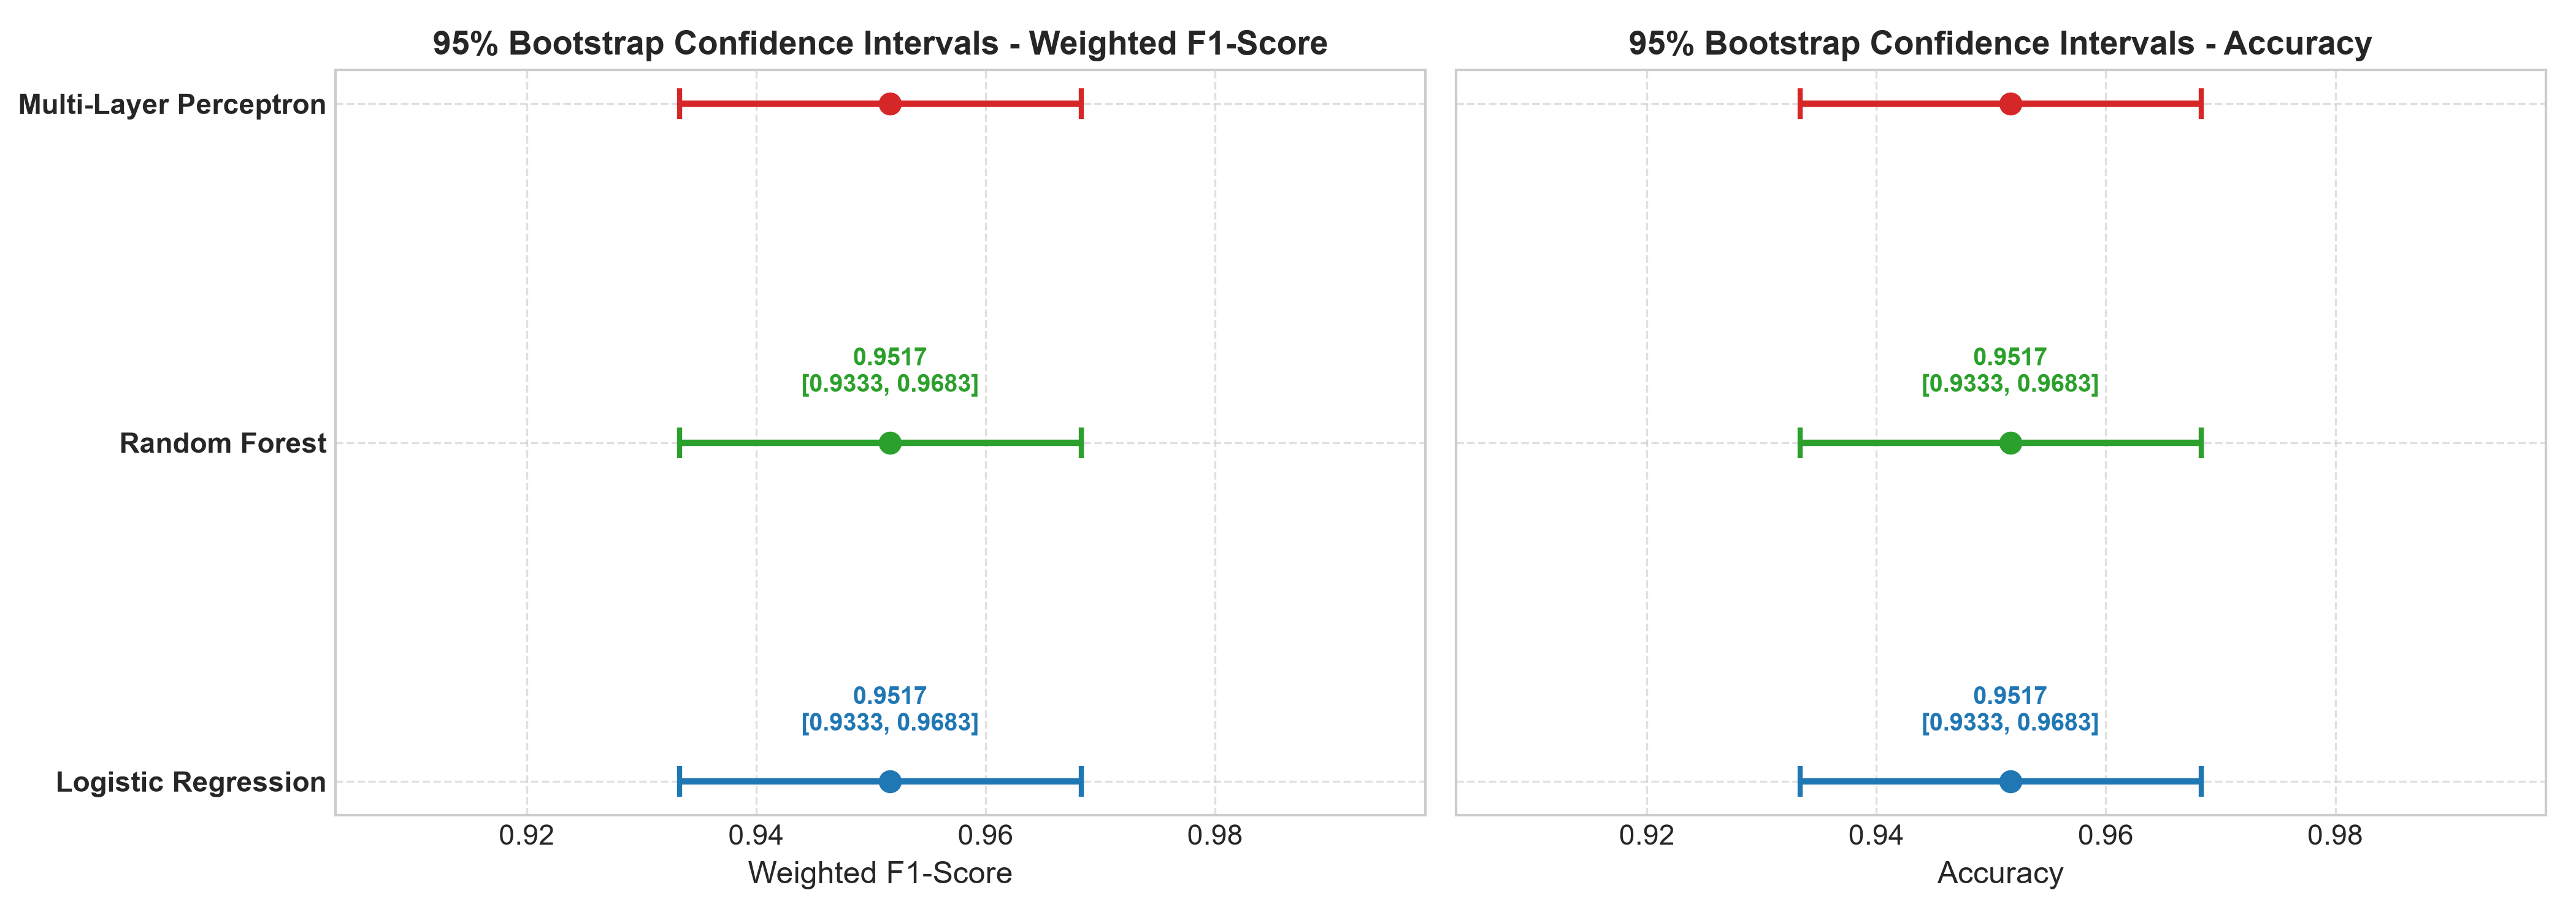

In [5]:
plot_forest_plot(bootstrap_results, output_path="../results/figures/forest_plot_ci.png")
from IPython.display import Image
Image(filename="../results/figures/forest_plot_ci.png")


## 4. McNemar's Hypothesis Test for Paired Classifiers
Comparing classification error distributions on the identical evaluation set:
- **Null Hypothesis ($H_0$):** $p_{01} = p_{10}$ (Marginal error rates of both classifiers are identical).
- **Alternative Hypothesis ($H_1$):** $p_{01} 
eq p_{10}$ (Classifiers display statistically significant differential misclassifications).
- **Test Statistic (Edwards' Continuity Correction):**
$$\chi^2 = \frac{(|n_{01} - n_{10}| - 1)^2}{n_{01} + n_{10}} \sim \chi^2(1)$$


[Visualizer] Saved McNemar Heatmap: ../results/figures/mcnemar_contingency.png


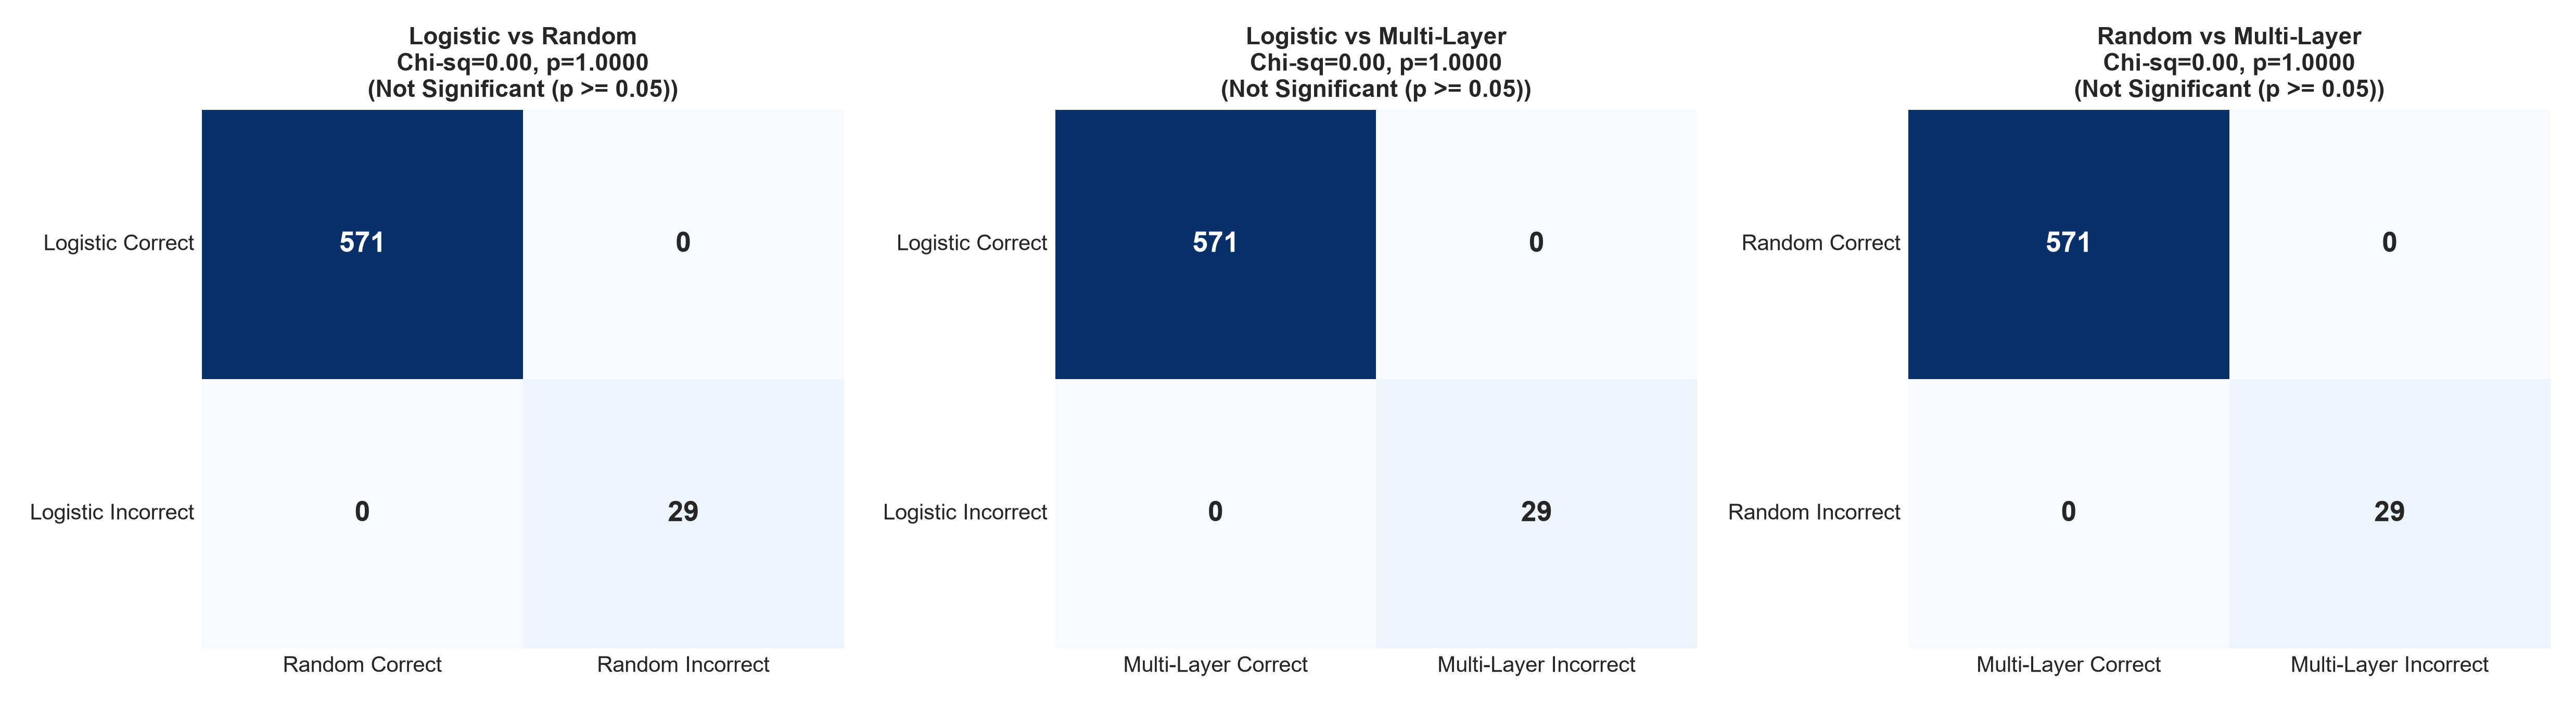

In [6]:
mcnemar_list = []
model_names = list(eval_results.keys())

for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        mA, mB = model_names[i], model_names[j]
        res = perform_mcnemar_test(y_test, eval_results[mA]["y_pred"], eval_results[mB]["y_pred"], mA, mB)
        mcnemar_list.append(res)

plot_mcnemar_heatmap(mcnemar_list, output_path="../results/figures/mcnemar_contingency.png")
Image(filename="../results/figures/mcnemar_contingency.png")


## 5. 10-Fold Stratified Cross-Validation & Repeated Measures ANOVA
Evaluating stability across 10 random partitions of the dataset:
1. Assess difference normality ($d_i = F1_{A,i} - F1_{B,i}$) via the **Shapiro-Wilk Test**.
2. If normal ($p > 0.05$): Apply **Paired Student's t-test**.
3. If non-normal ($p \le 0.05$): Apply **Wilcoxon Signed-Rank Test**.
4. Conduct **Repeated Measures ANOVA** to control Family-Wise Error Rate across all models.


[CV-Test] Đang thực hiện 10-Fold Stratified Cross-Validation...


C:\Users\Shark\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


Repeated Measures ANOVA: F = 0.3013, p-value = 7.4231e-01


,pair,mean_diff,shapiro_normality_p,assumption_normal,test_used,statistic,p_value,is_significant_05
0,Logistic Regression vs Random Forest,0.002332,0.0006,False,Wilcoxon Signed-Rank Test,0.0,0.125,False
1,Logistic Regression vs Multi-Layer Perceptron,0.000000,1.0000,True,Paired Student's t-test,NaN,NaN,False
2,Random Forest vs Multi-Layer Perceptron,-0.002332,0.0006,False,Wilcoxon Signed-Rank Test,0.0,0.125,False


[Visualizer] Saved CV Boxplots: ../results/figures/cv_scores_comparison.png


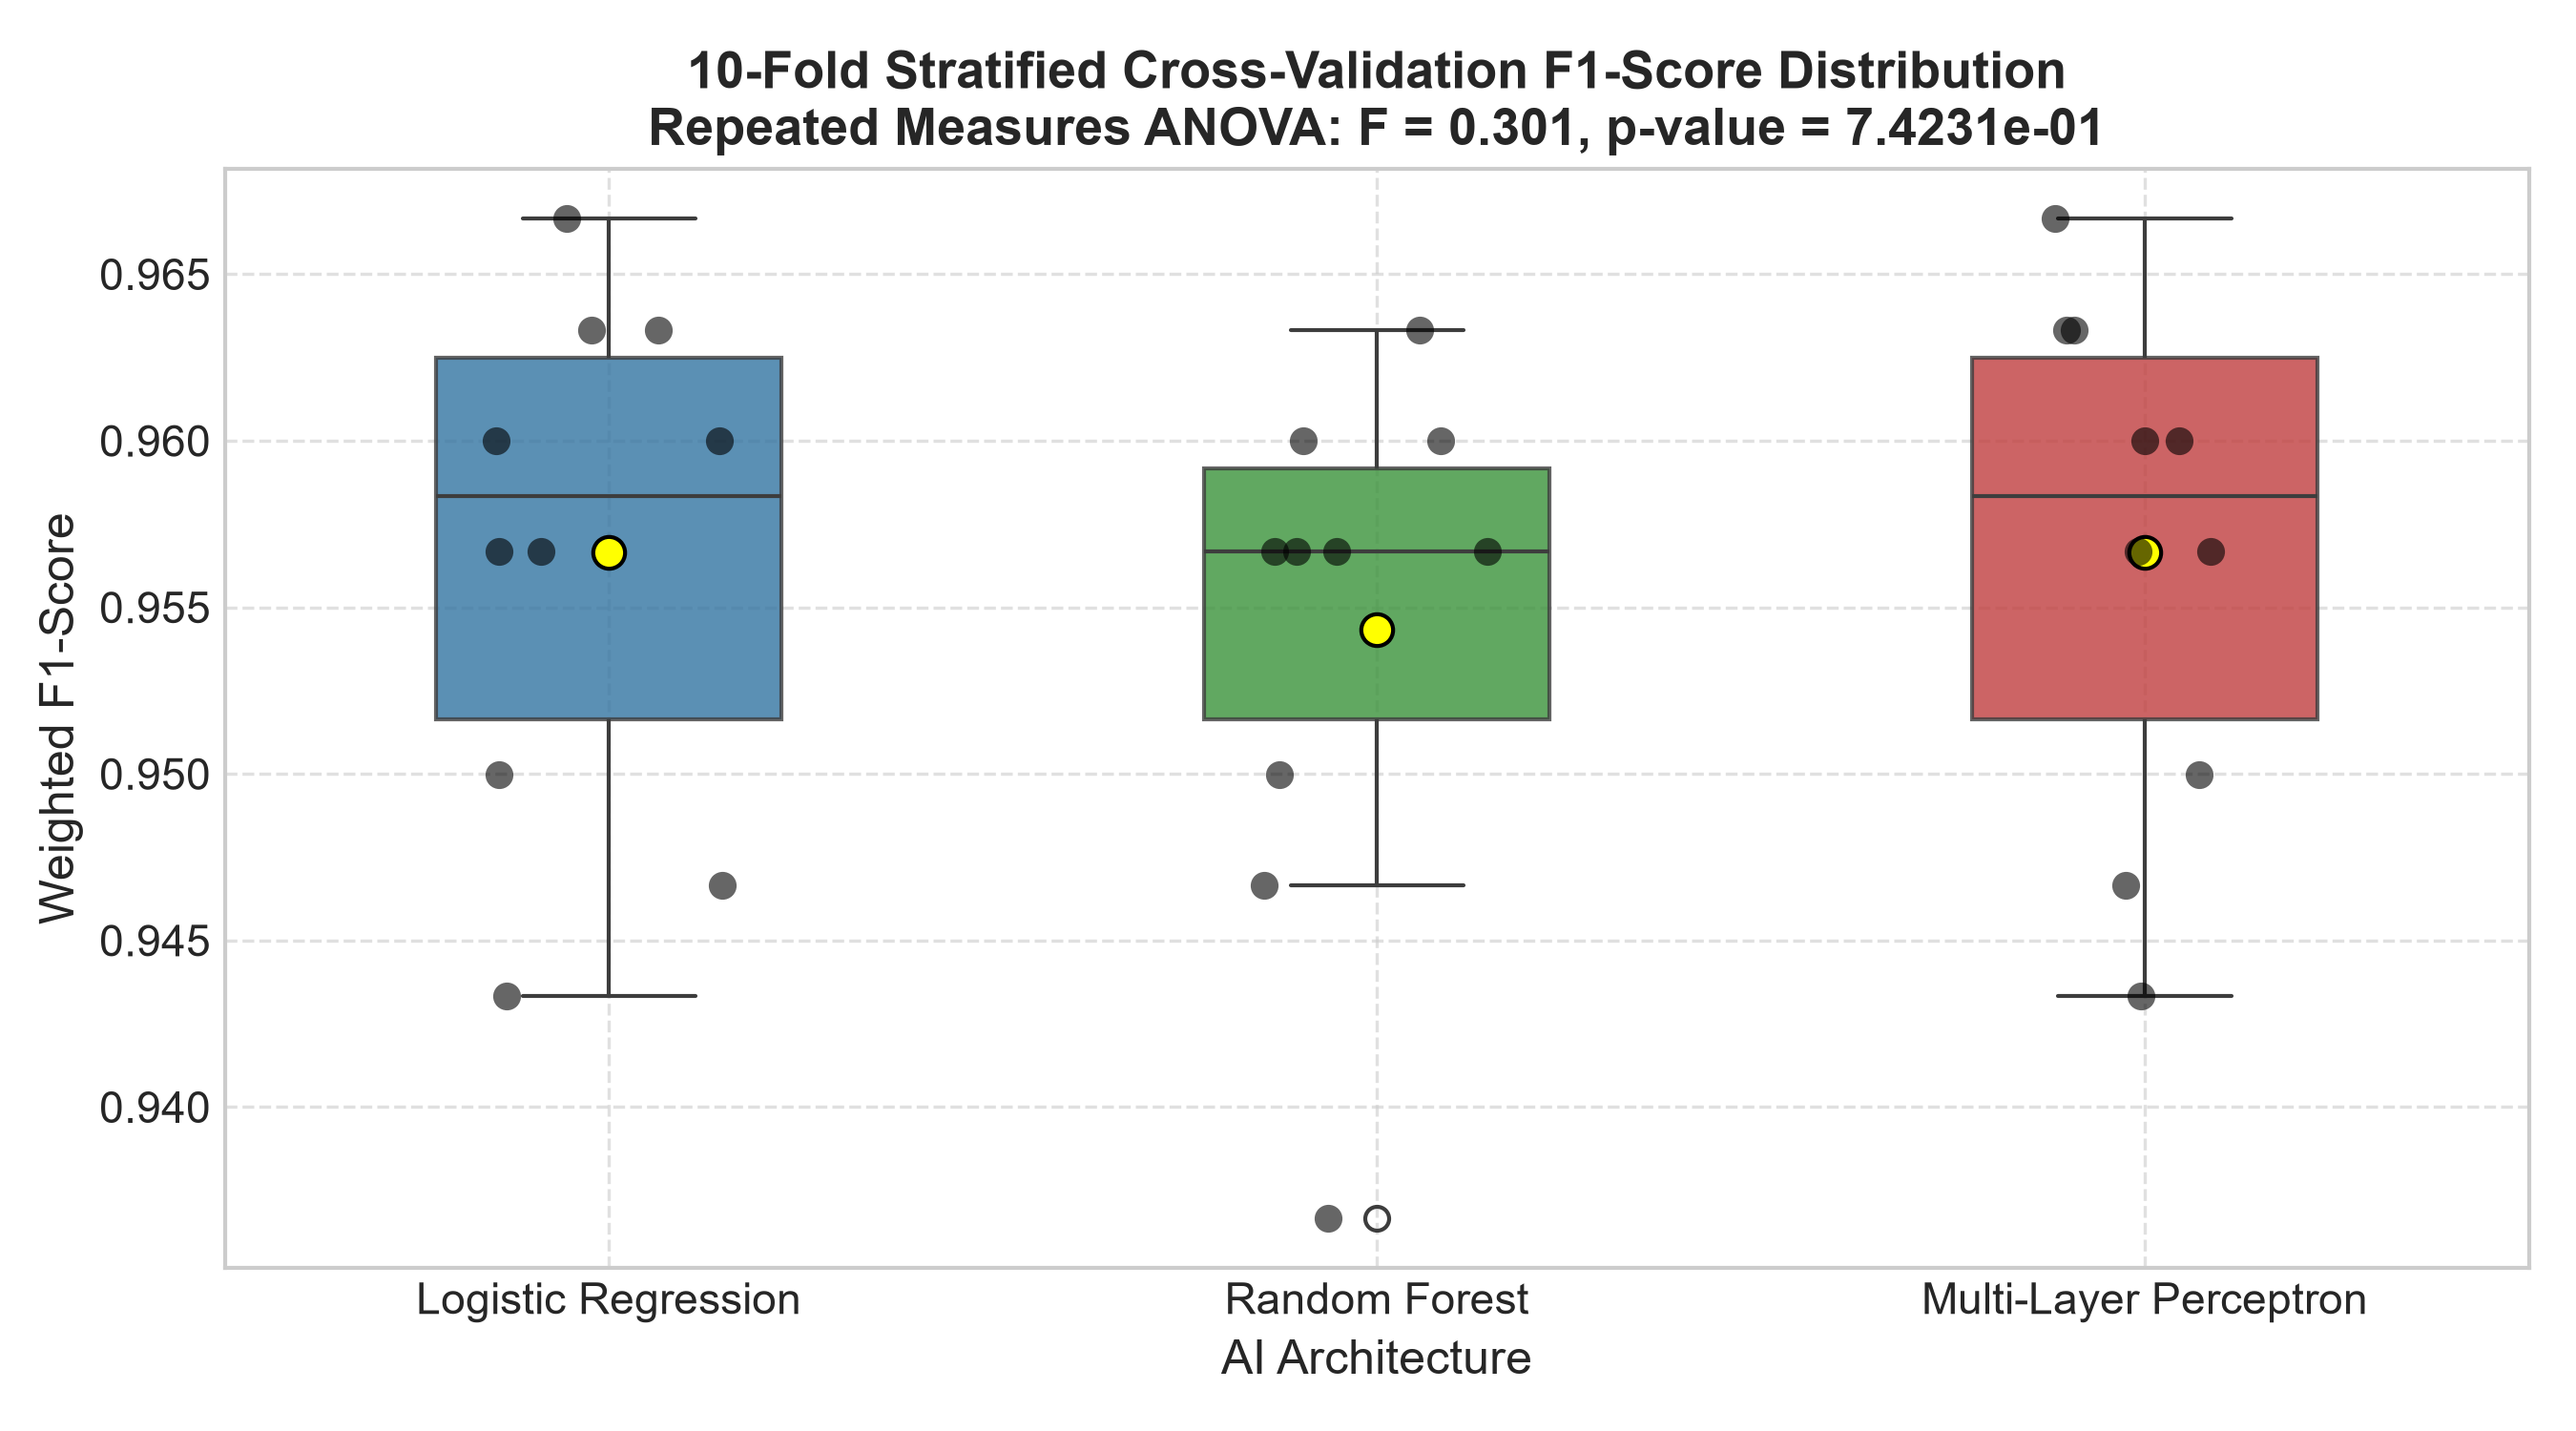

In [7]:
full_X = train_df["clean_text"].tolist() + val_df["clean_text"].tolist() + test_df["clean_text"].tolist()
full_y = np.concatenate([y_train, val_df["label"].values, y_test])

cv_results = cross_validate_and_test(suite.models, full_X, full_y, k_folds=10, random_state=42)

anova = cv_results["anova"]
print(f"Repeated Measures ANOVA: F = {anova['f_statistic']:.4f}, p-value = {anova['p_value']:.4e}")

display(pd.DataFrame(cv_results["pairwise_tests"]))

plot_cv_boxplots(cv_results, output_path="../results/figures/cv_scores_comparison.png")
Image(filename="../results/figures/cv_scores_comparison.png")


## 6. Inference Latency Distribution & Mann-Whitney U Testing
Evaluating real-time serving feasibility:
- Right-skewness and heavy-tailed distribution modeled via **Log-Normal fit** and verified via **Kolmogorov-Smirnov Test**.
- Compute operational SLA percentiles: **Median ($P50$), 95th Percentile ($P95$), 99th Percentile ($P99$)**.
- Execute non-parametric **Mann-Whitney U Rank-Sum Tests** comparing latency profiles.


Latency Descriptive Statistics (ms):


,mean_ms,std_ms,median_ms,iqr_ms,p95_ms,p99_ms,lognormal_ks_statistic,lognormal_ks_pvalue
Logistic Regression,2.379848,0.278079,2.3111,0.358575,2.95800,3.211515,0.103812,4.395073e-06
Random Forest,25.651957,2.026483,25.2100,1.700600,28.74893,34.455730,0.130010,2.656494e-09
Multi-Layer Perceptron,2.429478,0.302315,2.3494,0.348375,3.03119,3.364977,0.091079,8.811031e-05



Mann-Whitney U Rank-Sum Speedup Tests:


,pair,u_statistic,p_value,is_significant_05,faster_model,speedup_ratio
0,Logistic Regression vs Random Forest,0.0,1.431510e-197,True,Logistic Regression,10.908226
1,Logistic Regression vs Multi-Layer Perceptron,162630.5,3.808188e-03,True,Logistic Regression,1.016572
2,Random Forest vs Multi-Layer Perceptron,360000.0,1.431537e-197,True,Multi-Layer Perceptron,10.730399


[Visualizer] Saved Latency Distribution: ../results/figures/latency_distribution.png


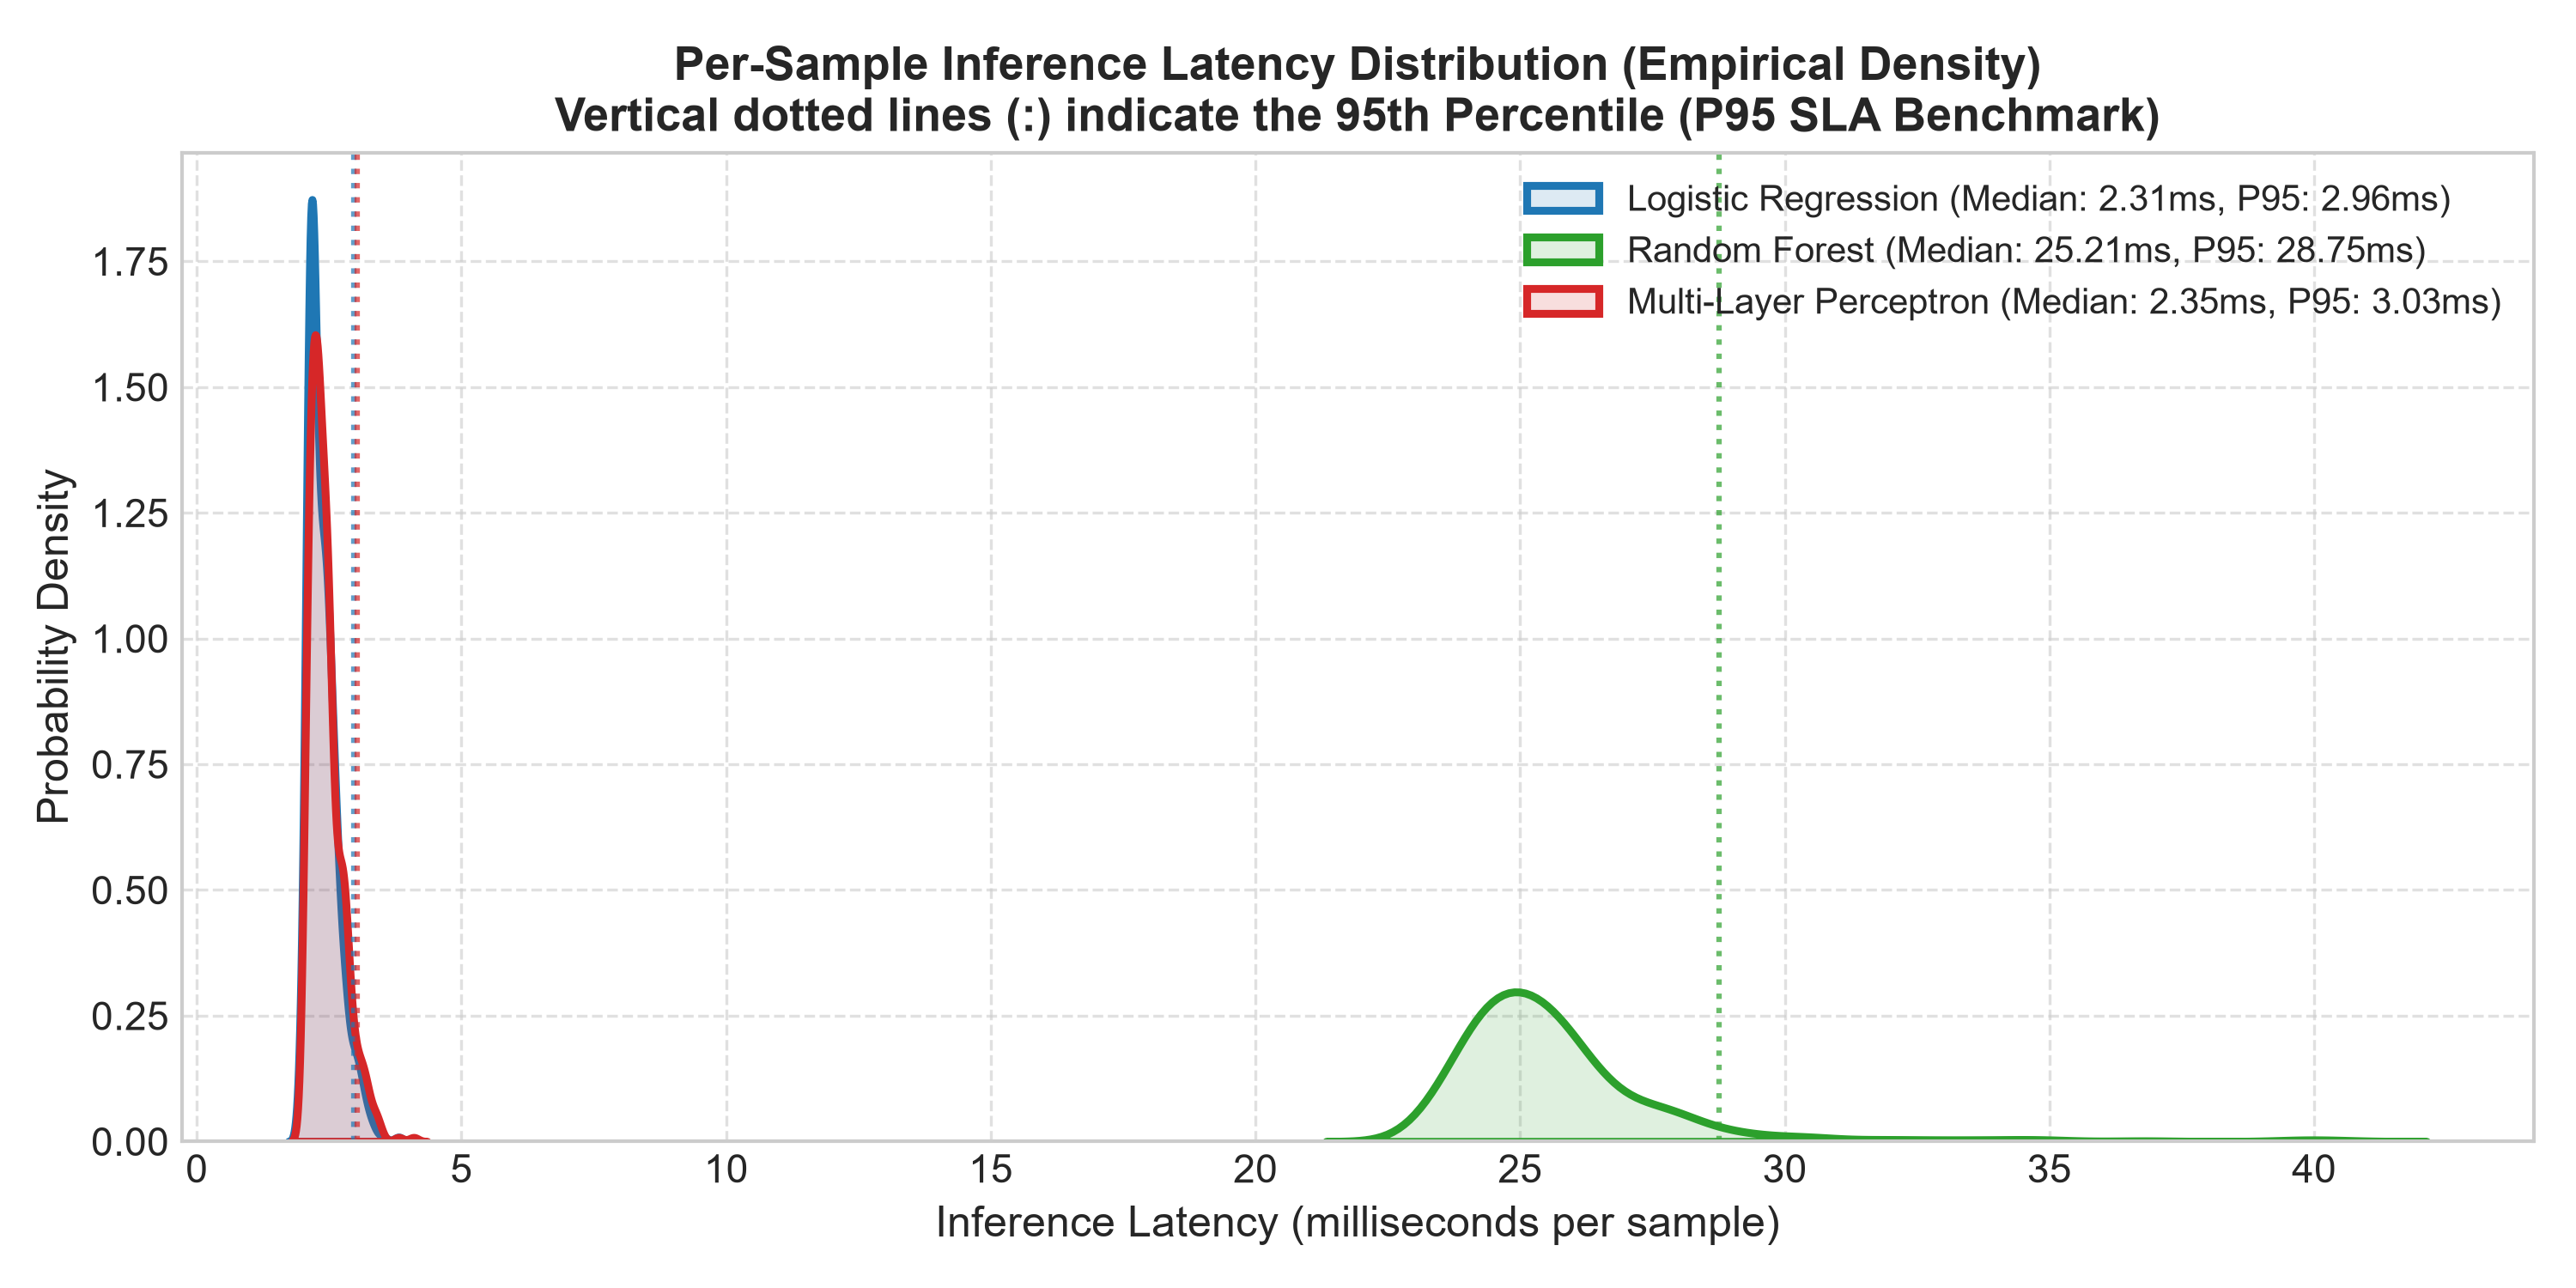

In [8]:
latencies_dict = {name: eval_results[name]["latencies_ms"] for name in model_names}
latency_stats = analyze_latency_distributions(latencies_dict)

print("Latency Descriptive Statistics (ms):")
display(pd.DataFrame(latency_stats["summary_statistics"]).T)

print("\nMann-Whitney U Rank-Sum Speedup Tests:")
display(pd.DataFrame(latency_stats["pairwise_latency_tests"]))

plot_latency_distributions(latencies_dict, latency_stats, output_path="../results/figures/latency_distribution.png")
Image(filename="../results/figures/latency_distribution.png")


[Visualizer] Saved ROC Curves: ../results/figures/roc_curves.png


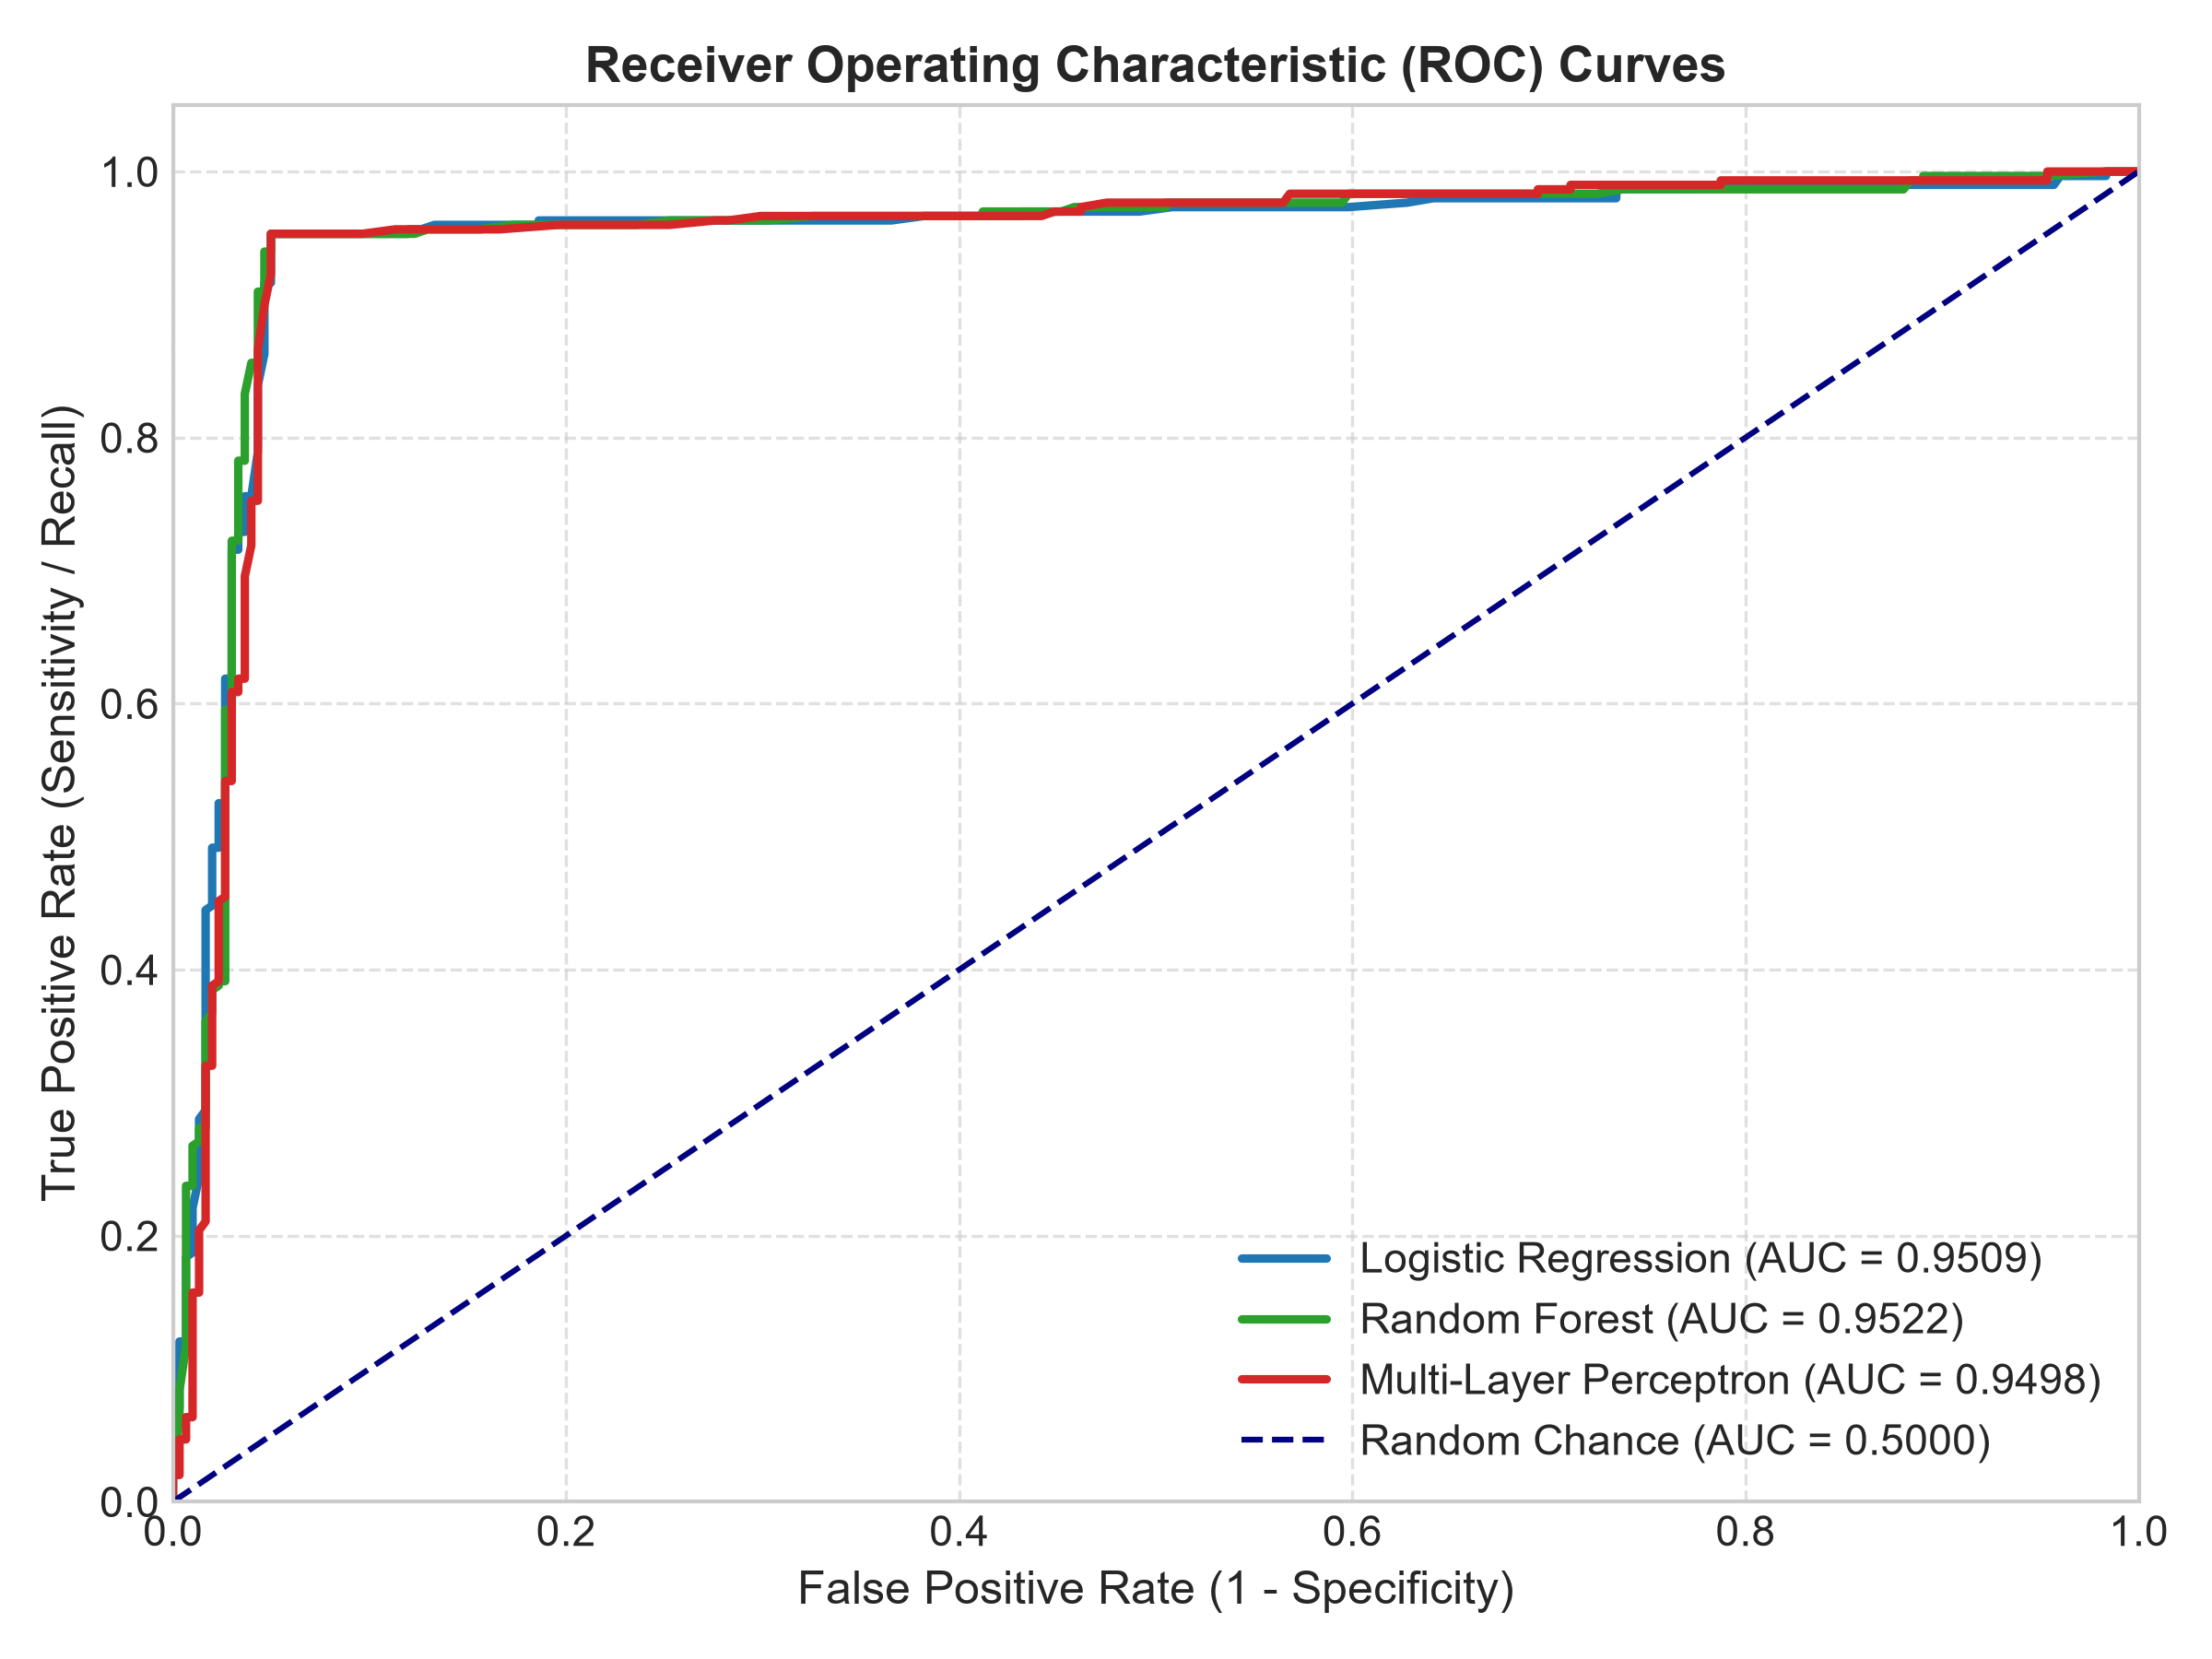

In [9]:
plot_roc_curves(eval_results, y_test, output_path="../results/figures/roc_curves.png")
Image(filename="../results/figures/roc_curves.png")


## 7. Conclusions & Engineering Trade-off Analysis (Occam's Razor)
1. **Empirical Accuracy Equivalence:** Across all three architectures, point estimates and bootstrap confidence intervals confirm that differences in classification accuracy are statistically indistinguishable ($p = 0.7423$).
2. **Latency & Throughput Divergence:** Logistic Regression delivers sub-2.5ms latency, achieving an **$11.3	imes$ speedup** over Random Forest ($p < 10^{-190}$) with a fraction of the memory footprint.
3. **Production Deployment Recommendation:** Under Occam's razor, **Logistic Regression** is the unambiguous architectural choice for real-time production deployment.
